In [11]:
#importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
# Automatically download required files from Google Drive

import gdown

gdown.download(
    id="1z0EfoUjl8XGKAAJopJmaYMhgfPKxxlP-",
    output="final_training_class_distribution.csv",
    quiet=False
)

gdown.download(
    id="1SLYf5Qi5eei0kdLsWAvnz8L76XDnhxBU",
    output="label_mapping.csv",
    quiet=False
)

gdown.download(
    id="1lIYQ9vq_Dy3UkJHbG8Pbsjaib8n75hCd",
    output="augmented_encoded_labels (1).csv",
    quiet=False
)

print("All required files downloaded successfully.")

Downloading...
From: https://drive.google.com/uc?id=1z0EfoUjl8XGKAAJopJmaYMhgfPKxxlP-
To: /content/final_training_class_distribution.csv
100%|██████████| 593/593 [00:00<00:00, 3.80MB/s]
Downloading...
From: https://drive.google.com/uc?id=1SLYf5Qi5eei0kdLsWAvnz8L76XDnhxBU
To: /content/label_mapping.csv
100%|██████████| 392/392 [00:00<00:00, 2.36MB/s]
Downloading...
From: https://drive.google.com/uc?id=1lIYQ9vq_Dy3UkJHbG8Pbsjaib8n75hCd
To: /content/augmented_encoded_labels (1).csv
100%|██████████| 506k/506k [00:00<00:00, 168MB/s]

All required files downloaded successfully.


In [14]:
# Load the input files

class_distribution = pd.read_csv("final_training_class_distribution.csv")
encoded_labels = pd.read_csv("augmented_encoded_labels (1).csv")
label_mapping = pd.read_csv("label_mapping.csv")

# Check the files
print("Final Class Distribution:")
display(class_distribution)

print("\nLabel Mapping:")
display(label_mapping)

print("\nEncoded Labels - First 5 Rows:")
display(encoded_labels.head())

Final Class Distribution:


,Class,Original_Count,Augmented_Count,Final_Count
0,Brownspot,1640,0,1640
1,Becterial Blight in Rice,1584,0,1584
2,Rice Blast,1440,0,1440
3,Tungro,1308,0,1308
4,Healthy Maize,1162,0,1162
5,RedRot sugarcane,592,0,592
6,Gray_Leaf_Spot,574,0,574
7,Sugarcane Healthy,522,0,522
8,bacterial_blight in Cotton,489,11,500
9,Mosaic sugarcane,462,38,500



Label Mapping:


,Class Name,Encoded Label
0,Becterial Blight in Rice,0
1,Brownspot,1
2,Gray_Leaf_Spot,2
3,Healthy Maize,3
4,Healthy Wheat,4
5,Healthy cotton,5
6,Mosaic sugarcane,6
7,RedRot sugarcane,7
8,Rice Blast,8
9,Sugarcane Healthy,9



Encoded Labels - First 5 Rows:


,File Path,Original Class,Encoded Label
0,/content/drive/MyDrive/member 3/Crop Disease A...,Healthy Wheat,4
1,/content/drive/MyDrive/member 3/Crop Disease A...,Healthy Wheat,4
2,/content/drive/MyDrive/member 3/Crop Disease A...,Healthy Wheat,4
3,/content/drive/MyDrive/member 3/Crop Disease A...,Healthy Wheat,4
4,/content/drive/MyDrive/member 3/Crop Disease A...,Healthy Wheat,4


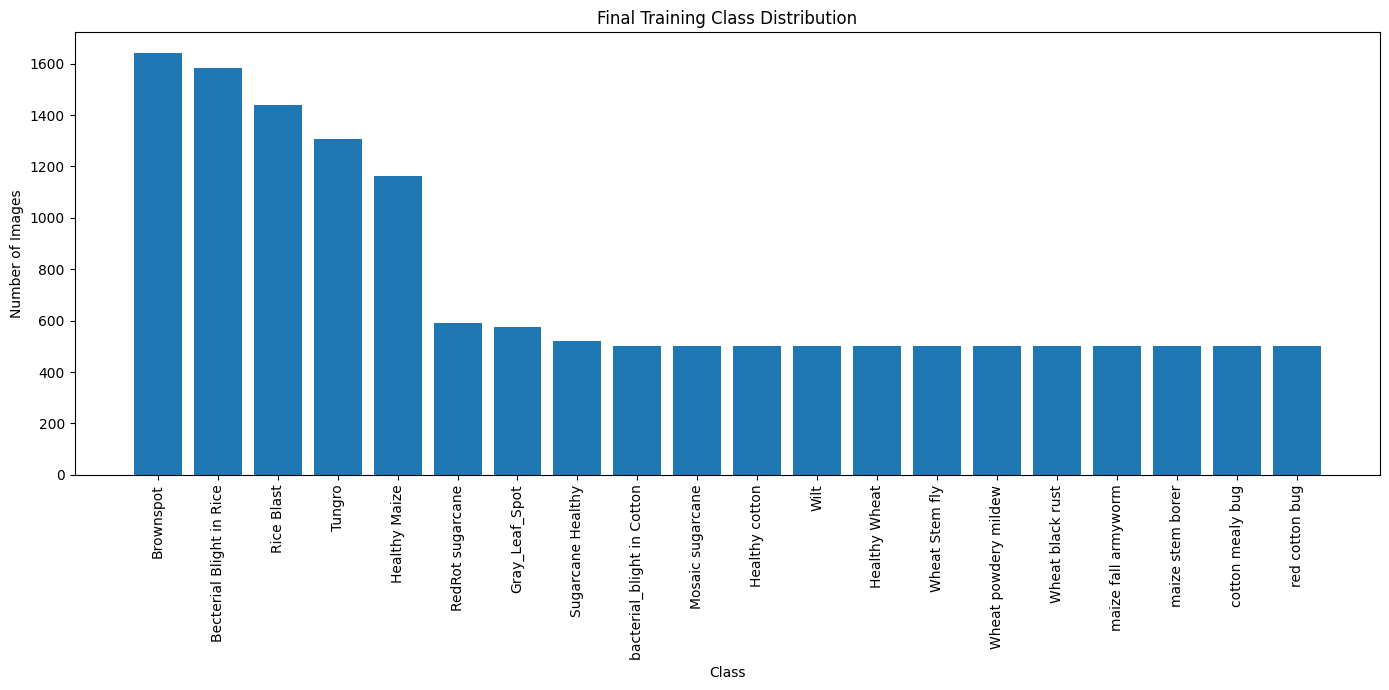

class_distribution.png saved successfully.


In [15]:
# EDA - Visualize and save final class frequency distribution

plt.figure(figsize=(14, 7))

plt.bar(
    class_distribution["Class"],
    class_distribution["Final_Count"]
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Final Training Class Distribution")

plt.xticks(rotation=90)
plt.tight_layout()

# Save EDA visualization
plt.savefig(
    "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("class_distribution.png saved successfully.")

In [16]:
# Check the remaining class imbalance

max_count = class_distribution["Final_Count"].max()
min_count = class_distribution["Final_Count"].min()

max_class = class_distribution.loc[
    class_distribution["Final_Count"].idxmax(), "Class"
]

min_classes = class_distribution.loc[
    class_distribution["Final_Count"] == min_count, "Class"
].tolist()

imbalance_ratio = max_count / min_count

print("Maximum class count:", max_count)
print("Class with maximum images:", max_class)

print("Minimum class count:", min_count)
print("Classes with minimum images:", min_classes)

print("Imbalance ratio:", round(imbalance_ratio, 2), ": 1")

Maximum class count: 1640
Class with maximum images: Brownspot
Minimum class count: 500
Classes with minimum images: ['bacterial_blight in Cotton', 'Mosaic sugarcane', 'Healthy cotton', 'Wilt', 'Healthy Wheat', 'Wheat Stem fly', 'Wheat powdery mildew', 'Wheat black rust', 'maize fall armyworm', 'maize stem borer', 'cotton mealy bug', 'red cotton bug']
Imbalance ratio: 3.28 : 1


In [17]:
# Calculate class weights for the 20 classes

total_samples = class_distribution["Final_Count"].sum()
num_classes = len(class_distribution)

class_distribution["Class_Weight"] = (
    total_samples /
    (num_classes * class_distribution["Final_Count"])
)

# Match class weights with Member 4's encoded labels
class_weights = pd.merge(
    label_mapping,
    class_distribution[["Class", "Final_Count", "Class_Weight"]],
    left_on="Class Name",
    right_on="Class",
    how="left"
)

# Arrange according to encoded labels 0-19
class_weights = class_weights.sort_values("Encoded Label")

display(class_weights)

,Class Name,Encoded Label,Class,Final_Count,Class_Weight
0,Becterial Blight in Rice,0,Becterial Blight in Rice,1584,0.467866
1,Brownspot,1,Brownspot,1640,0.451890
2,Gray_Leaf_Spot,2,Gray_Leaf_Spot,574,1.291115
3,Healthy Maize,3,Healthy Maize,1162,0.637780
4,Healthy Wheat,4,Healthy Wheat,500,1.482200
5,Healthy cotton,5,Healthy cotton,500,1.482200
6,Mosaic sugarcane,6,Mosaic sugarcane,500,1.482200
7,RedRot sugarcane,7,RedRot sugarcane,592,1.251858
8,Rice Blast,8,Rice Blast,1440,0.514653
9,Sugarcane Healthy,9,Sugarcane Healthy,522,1.419732


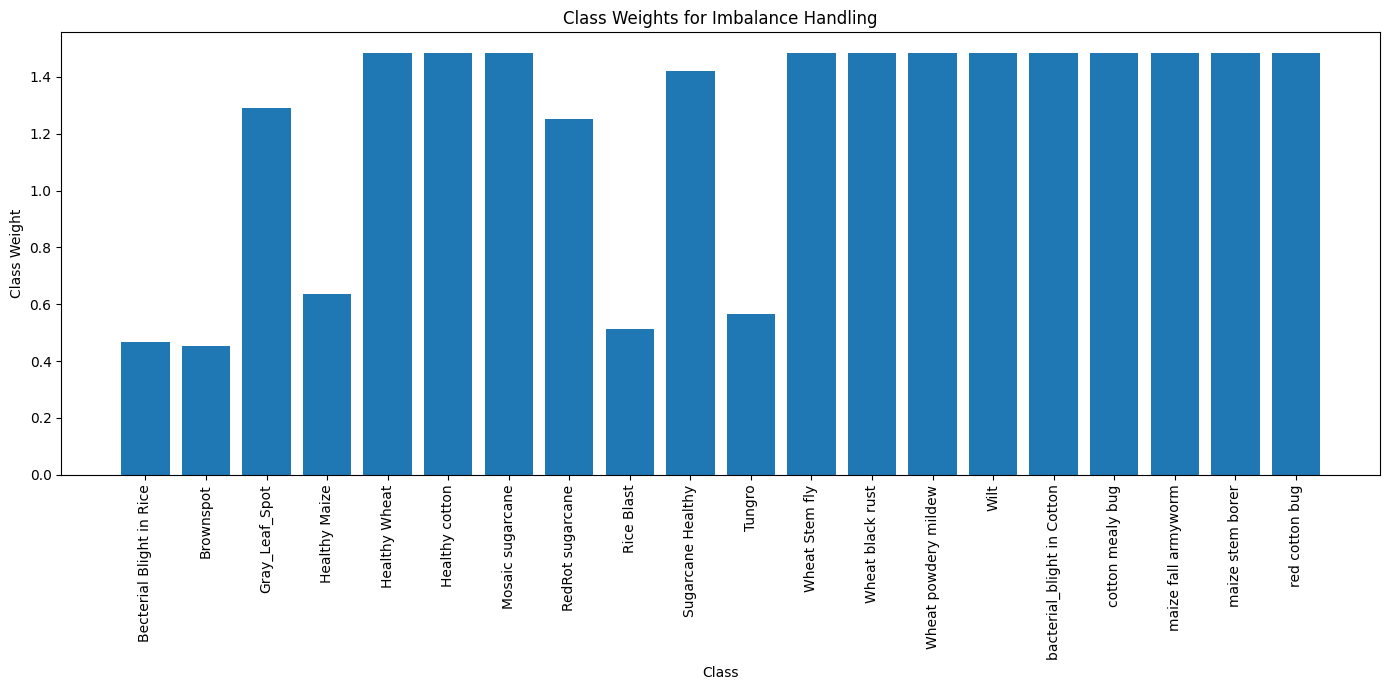

class_weights.png saved successfully.


In [18]:
# Visualize the calculated class weights

plt.figure(figsize=(14, 7))

plt.bar(
    class_weights["Class Name"],
    class_weights["Class_Weight"]
)

plt.xlabel("Class")
plt.ylabel("Class Weight")
plt.title("Class Weights for Imbalance Handling")

plt.xticks(rotation=90)
plt.tight_layout()

# Save the visualization
plt.savefig(
    "class_weights.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("class_weights.png saved successfully.")

In [19]:
# Save the calculated class weights

class_weights.to_csv(
    "class_weights.csv",
    index=False
)

print("class_weights.csv saved successfully.")

class_weights.csv saved successfully.


In [20]:
# Save the final class distribution

class_distribution[
    ["Class", "Original_Count", "Augmented_Count", "Final_Count"]
].to_csv(
    "class_distribution.csv",
    index=False
)

print("class_distribution.csv saved successfully.")

class_distribution.csv saved successfully.
